# 14. Coupon theo Label

Phân tích coupon usage, redemption recency và coupon discount trong 90 ngày trước cutoff.

## Notebook này làm gì

So sánh coupon usage và redemption behavior giữa Positive và Negative label.

### Nội dung đã thực hiện

- Build coupon feature leakage-safe trong 90 ngày trước cutoff.
- Phân tích ever redeemed, số redemption và positive rate.
- Phân tích days since last redemption.
- So sánh tổng COUPON_DISC và COUPON_MATCH_DISC theo label.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.coupon_label import load_coupon_label_report
from propensity.eda.coupon_label_plots import (
    plot_coupon_feature_boxplots,
    plot_coupon_usage_by_label_stacked,
    plot_coupon_user_positive_rate,
)

## 1. Build leakage-safe coupon features

In [2]:
project_root = Path.cwd().resolve()
if project_root.name in ("notebooks", "draft_notebooks"):
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw" / "Dunnhumby"
label_path = (
    project_root
    / "data"
    / "processed"
    / "purchase_propensity_t90_h7_step7"
    / "household_cutoff_labels.parquet"
)

report = load_coupon_label_report(
    label_path,
    raw_dir,
    observation_days=90,
)

## 2. Định nghĩa feature

| Feature | Định nghĩa |
|---|---|
| `ever_coupon_redeemed_90d` | Có ít nhất một redemption event trong window |
| `n_coupon_redemptions_90d` | Số event unique theo household–day–coupon–campaign |
| `days_since_last_coupon_redemption` | `cutoff_day - last_redemption_day`; null nếu chưa từng redeem trong window |
| `total_coupon_discount_90d` | Tổng độ lớn của `COUPON_DISC < 0` |
| `total_coupon_match_discount_90d` | Tổng độ lớn của `COUPON_MATCH_DISC < 0` |

In [3]:
report.summary_by_label

,feature,label,n_observations,missing_rate,q1,median,q3
0,ever_coupon_redeemed_90d,0,94821,0.000000,0.0,0.0,0.00
1,ever_coupon_redeemed_90d,1,107423,0.000000,0.0,0.0,0.00
2,n_coupon_redemptions_90d,0,94821,0.000000,0.0,0.0,0.00
3,n_coupon_redemptions_90d,1,107423,0.000000,0.0,0.0,0.00
4,days_since_last_coupon_redemption,0,1472,0.984476,18.0,41.0,65.00
5,days_since_last_coupon_redemption,1,7958,0.925919,15.0,34.0,58.00
6,total_coupon_discount_90d,0,94821,0.000000,0.0,0.0,0.00
7,total_coupon_discount_90d,1,107423,0.000000,0.0,0.0,2.40
8,total_coupon_match_discount_90d,0,94821,0.000000,0.0,0.0,0.00
9,total_coupon_match_discount_90d,1,107423,0.000000,0.0,0.0,0.35


## 3. Coupon users và Positive rate

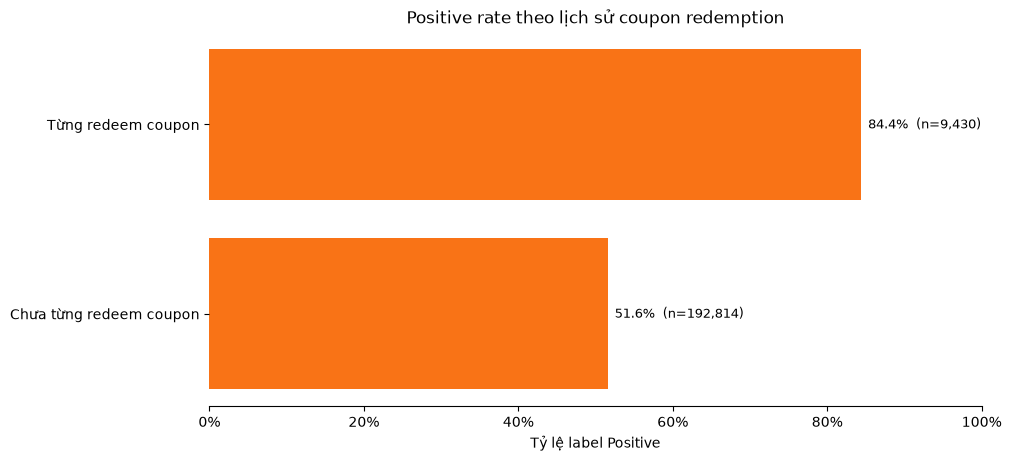

In [4]:
coupon_user_figure = plot_coupon_user_positive_rate(report.feature_panel)
plt.show()

## 4. Coupon responsiveness, recency và discount theo label

Box plot ẩn các điểm ngoại lai để tập trung vào P25–P75. Râu dùng quy tắc 1.5 × IQR.

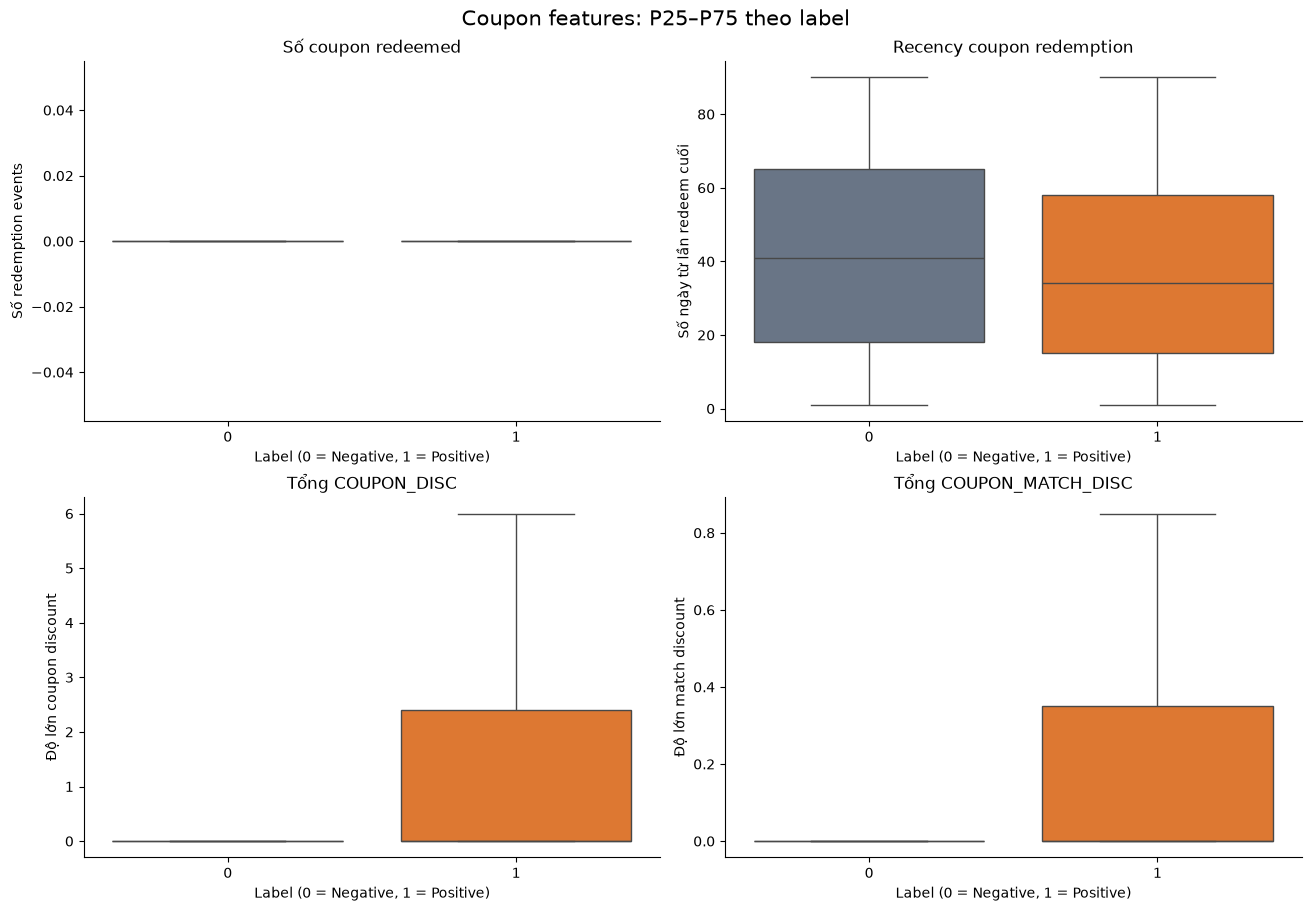

In [6]:
coupon_boxplots = plot_coupon_feature_boxplots(report.feature_panel)
plt.show()

## Lưu ý diễn giải

- Feature chỉ dùng dữ liệu trong `[cutoff-90, cutoff-1]`.
- Redemption count dùng event thật từ `coupon_redempt.csv`, không phải basket proxy.
- Recency chỉ so sánh những household có redemption trong window; household chưa redeem có giá trị null.
- Hai discount columns được đổi từ giá trị âm sang độ lớn dương trước khi cộng.
- Box plot ẩn outlier để tập trung P25–P75; dữ liệu không bị loại khỏi bước tính feature.
- Coupon history mô tả association, không chứng minh coupon gây ra label Positive.